In [2]:
pip install shap


   ---------------------------------------- 0.0/755.4 kB ? eta -:--:--
   ---------------------------------------- 755.4/755.4 kB 8.8 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
print(os.getcwd())
print([f for f in os.listdir() if f.endswith(".csv")])

C:\Users\dsanj\Python_Projects\cis
['drebin215dataset5560malware9476benign.csv', 'feature_vectors_syscallsbinders_frequency_5_Cat.csv']


In [6]:
import warnings
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

Removed 7782 duplicate/conflicting rows -> 7254 unique apps kept
Dataset: 7254 apps, 215 features
Benign: 5537 | Malware: 1717

=== HELD-OUT TEST RESULTS (20% of data) ===
                Accuracy  Precision  Recall      F1  ROC-AUC
Random Forest     0.9711     0.9602  0.9155  0.9373   0.9926
XGBoost           0.9800     0.9591  0.9563  0.9577   0.9961
Fused (RF+XGB)    0.9814     0.9675  0.9534  0.9604   0.9952
  fold 1/5 done
  fold 2/5 done
  fold 3/5 done
  fold 4/5 done
  fold 5/5 done

=== 5-FOLD CROSS-VALIDATION (mean ± std) ===
                       Accuracy        Precision           Recall               F1          ROC-AUC
Random Forest   0.9720 ± 0.0022  0.9721 ± 0.0132  0.9080 ± 0.0053  0.9389 ± 0.0044  0.9930 ± 0.0012
XGBoost         0.9763 ± 0.0036  0.9626 ± 0.0178  0.9365 ± 0.0080  0.9493 ± 0.0073  0.9952 ± 0.0017
Fused (RF+XGB)  0.9763 ± 0.0033  0.9681 ± 0.0157  0.9307 ± 0.0042  0.9490 ± 0.0066  0.9948 ± 0.0012


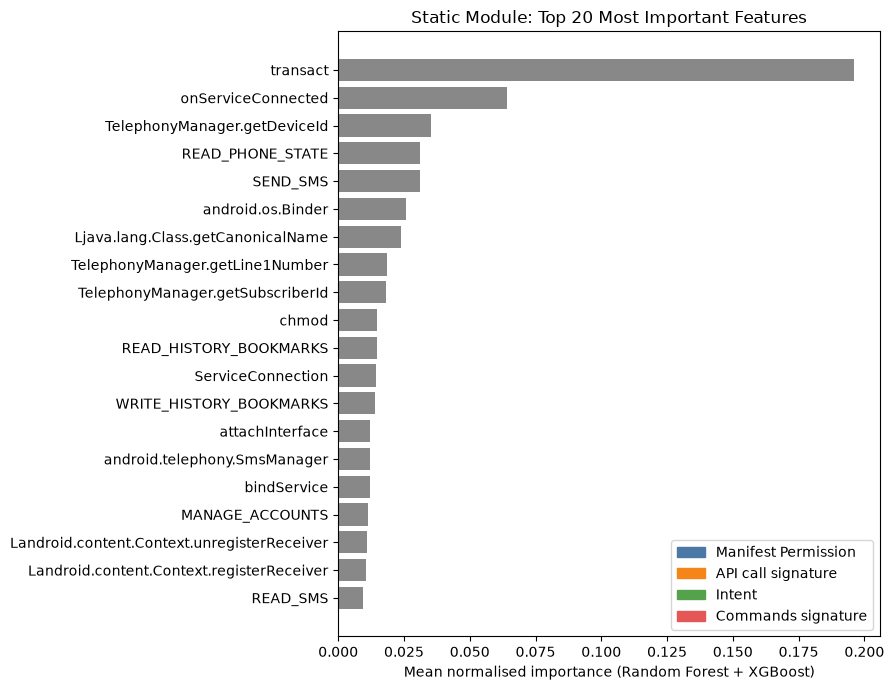


Top 10 features:
  1. transact  (0.1961)  [?]
  2. onServiceConnected  (0.0642)  [?]
  3. TelephonyManager.getDeviceId  (0.0354)  [?]
  4. READ_PHONE_STATE  (0.0312)  [?]
  5. SEND_SMS  (0.0310)  [?]
  6. android.os.Binder  (0.0259)  [?]
  7. Ljava.lang.Class.getCanonicalName  (0.0240)  [?]
  8. TelephonyManager.getLine1Number  (0.0186)  [?]
  9. TelephonyManager.getSubscriberId  (0.0181)  [?]
  10. chmod  (0.0148)  [?]


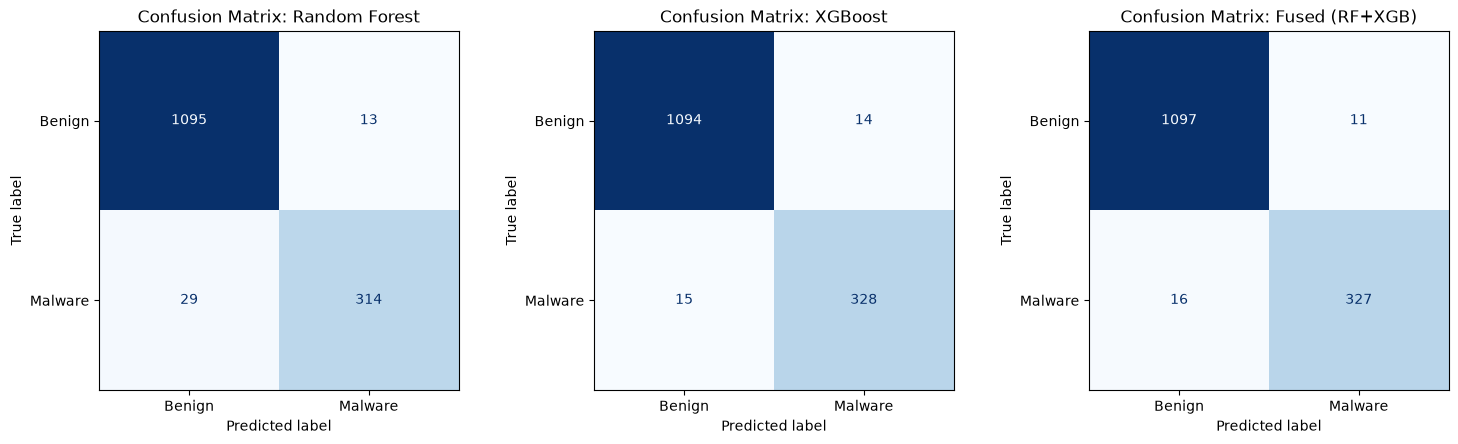

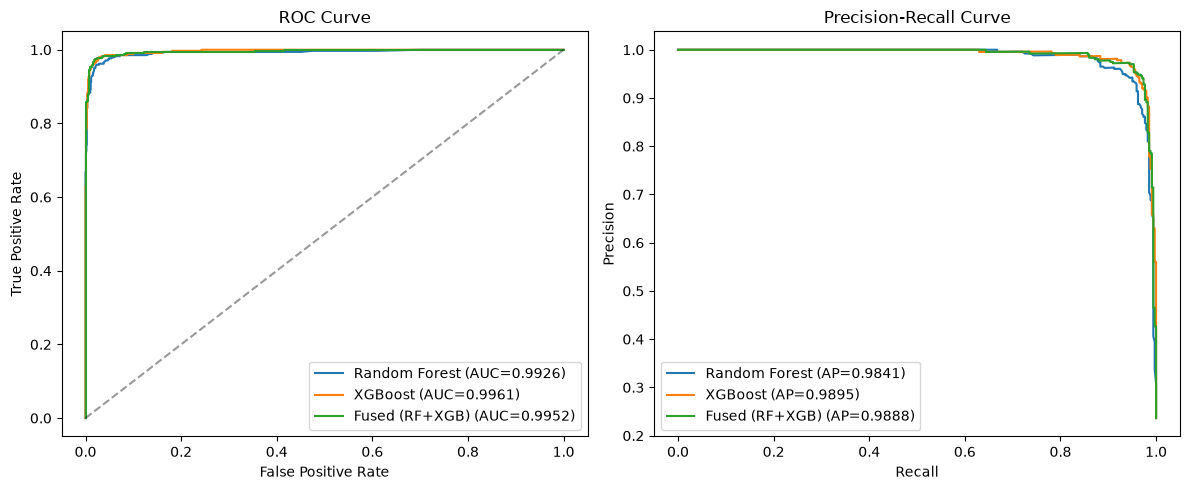

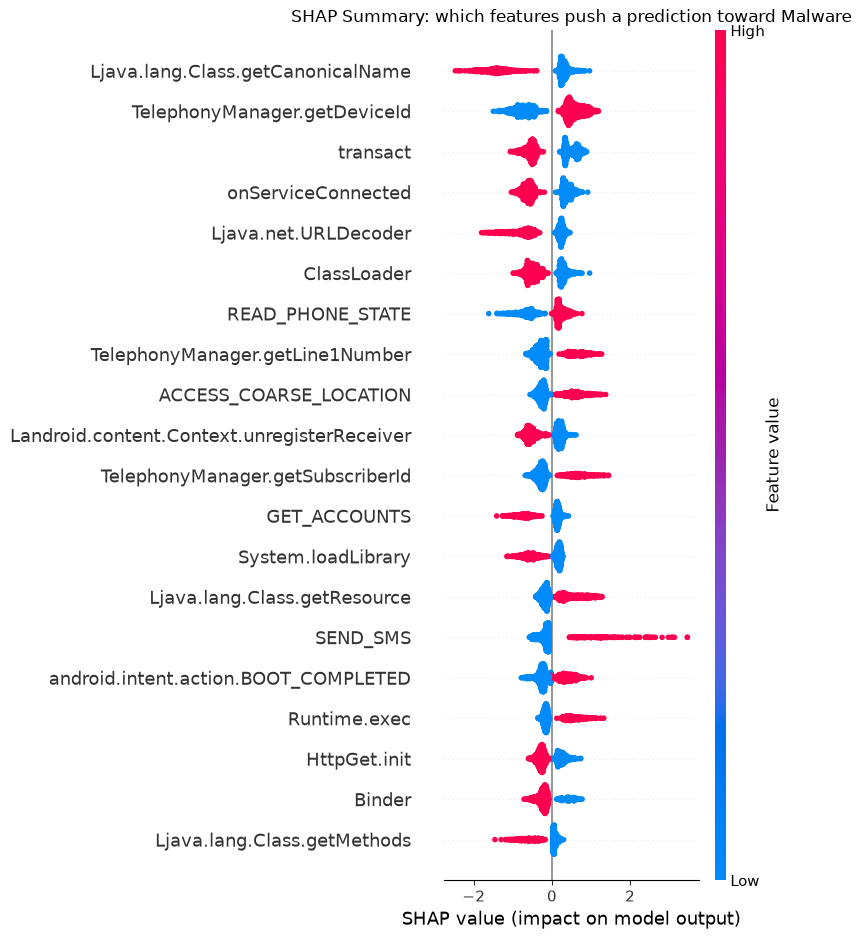

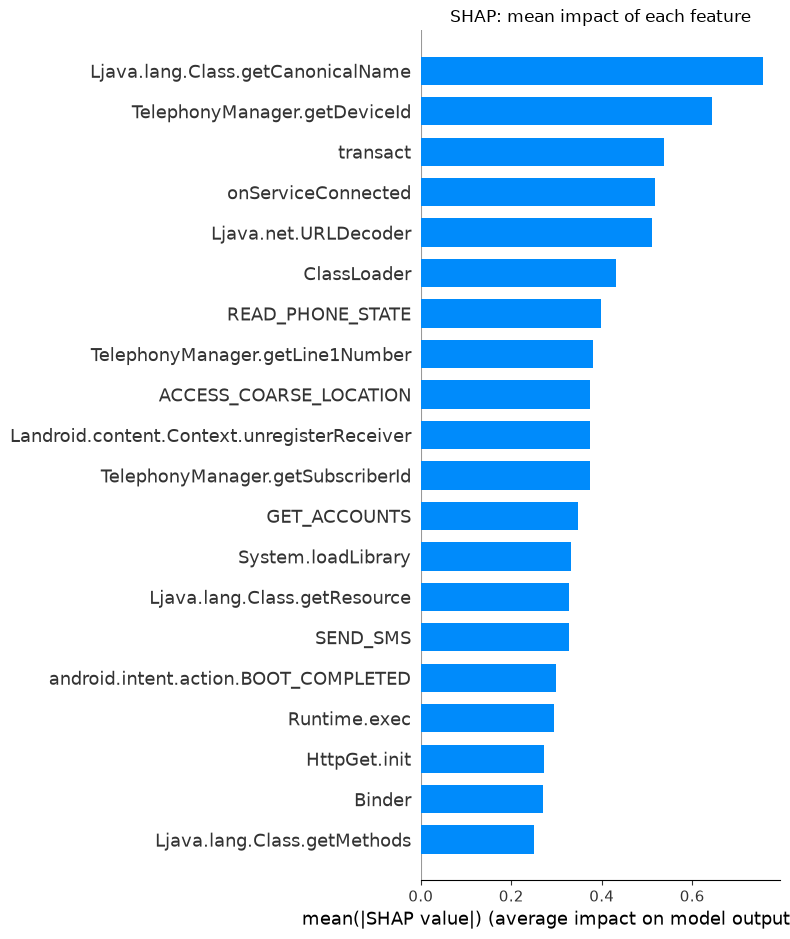


--- Example prediction (test app #1) ---
Prediction: MALWARE  | malware probability: 99.1%  | actual label: MALWARE
Top evidence (SHAP):
   android.intent.action.PACKAGE_REPLACED        present  -2.308  pushes toward BENIGN
   WRITE_HISTORY_BOOKMARKS                       present  +1.414  pushes toward MALWARE
   findClass                                     present  +1.040  pushes toward MALWARE
   TelephonyManager.getDeviceId                  present  +0.915  pushes toward MALWARE
   Ljava.lang.Class.getResource                  present  +0.884  pushes toward MALWARE
   READ_HISTORY_BOOKMARKS                        present  +0.868  pushes toward MALWARE

Saved model + results + plots to ./static_outputs1/


In [1]:
# =============================================================================
# PHASE 1: STATIC ANALYSIS MODULE  (Drebin-215)
# Random Forest + XGBoost -> fused prediction
# Feature importance, 5-fold CV, SHAP, confusion matrix, ROC, PR curve, save model
# =============================================================================
import os
import warnings
os.environ["PYTHONWARNINGS"] = "ignore"   # hides harmless joblib/sklearn warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, average_precision_score)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# -----------------------------------------------------------------------------
# >>> UPDATE THESE PATHS if your files are somewhere else <<<
# -----------------------------------------------------------------------------
CSV_PATH = "drebin215dataset5560malware9476benign.csv"
CAT_PATH = "dataset-features-categories.csv"
OUT_DIR = "static_outputs"                         # plots + saved model go here
os.makedirs(OUT_DIR, exist_ok=True)

# =============================================================================
# STEP 1: LOAD + CLEAN
# =============================================================================
df = pd.read_csv(CSV_PATH, low_memory=False)

# One column ('TelephonyManager.getSimCountryIso') contains a few '?' values.
# '?' = unknown, so we treat it as 0 (feature absent).
feature_cols = [c for c in df.columns if c != "class"]
for c in feature_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce").fillna(0).astype(int)

# ---- DEDUPLICATION -----------------------------------------------------------
# Many apps share an identical yes/no feature vector. If copies land in both the
# training and the test set, the test is not truly unseen and scores look too good.
# So: (a) drop vectors that appear with BOTH labels (label noise), (b) keep one copy
# of every remaining identical vector.
n_before = len(df)
_y = (df["class"] == "S").astype(int)
conflict = _y.groupby([df[c] for c in feature_cols]).transform("nunique") > 1
df = df[~conflict].drop_duplicates(subset=feature_cols).reset_index(drop=True)
print(f"Removed {n_before - len(df)} duplicate/conflicting rows -> {len(df)} unique apps kept")

X = df[feature_cols]
y = (df["class"] == "S").astype(int)      # S = Malware -> 1, B = Benign -> 0

print(f"Dataset: {X.shape[0]} apps, {X.shape[1]} features")
print(f"Benign: {(y == 0).sum()} | Malware: {(y == 1).sum()}")

# Feature -> category lookup (permission / API call / intent / command)
category_of = {}
if os.path.exists(CAT_PATH):
    cat = pd.read_csv(CAT_PATH, header=None)
    for feat, c in zip(cat[0], cat[1]):
        category_of[str(feat)] = str(c)
# The categories file has its first data row used as header in some copies; make sure it's included
CAT_COLORS = {"Manifest Permission": "#4C78A8", "API call signature": "#F58518",
              "Intent": "#54A24B", "Commands signature": "#E45756"}

# =============================================================================
# STEP 2: TRAIN / TEST SPLIT (80/20, stratified)
# =============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# =============================================================================
# STEP 3: MODELS
# =============================================================================
def make_rf():
    return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)

def make_xgb():
    return xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                             eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

rf = make_rf().fit(X_train, y_train)
xgb_model = make_xgb().fit(X_train, y_train)

# Static Fusion = average of the two probability outputs
def fuse(p_rf, p_xgb):
    return (p_rf + p_xgb) / 2.0

p_rf = rf.predict_proba(X_test)[:, 1]
p_xgb = xgb_model.predict_proba(X_test)[:, 1]
p_fused = fuse(p_rf, p_xgb)

def metrics(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, prob)}

test_results = pd.DataFrame({
    "Random Forest": metrics(y_test, p_rf),
    "XGBoost": metrics(y_test, p_xgb),
    "Fused (RF+XGB)": metrics(y_test, p_fused)}).T
print("\n=== HELD-OUT TEST RESULTS (20% of data) ===")
print(test_results.round(4).to_string())

# =============================================================================
# STEP 4: 5-FOLD STRATIFIED CROSS-VALIDATION
# =============================================================================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = {"Random Forest": [], "XGBoost": [], "Fused (RF+XGB)": []}
for fold, (tr, va) in enumerate(skf.split(X, y), 1):
    Xtr, Xva, ytr, yva = X.iloc[tr], X.iloc[va], y.iloc[tr], y.iloc[va]
    m_rf, m_xgb = make_rf().fit(Xtr, ytr), make_xgb().fit(Xtr, ytr)
    pr, px = m_rf.predict_proba(Xva)[:, 1], m_xgb.predict_proba(Xva)[:, 1]
    cv_rows["Random Forest"].append(metrics(yva, pr))
    cv_rows["XGBoost"].append(metrics(yva, px))
    cv_rows["Fused (RF+XGB)"].append(metrics(yva, fuse(pr, px)))
    print(f"  fold {fold}/5 done")

cv_summary = {}
for name, rows in cv_rows.items():
    d = pd.DataFrame(rows)
    cv_summary[name] = {k: f"{d[k].mean():.4f} ± {d[k].std():.4f}" for k in d.columns}
cv_table = pd.DataFrame(cv_summary).T
print("\n=== 5-FOLD CROSS-VALIDATION (mean ± std) ===")
print(cv_table.to_string())

# =============================================================================
# STEP 5: FEATURE IMPORTANCE (top 20, coloured by feature category)
# =============================================================================
def norm(v):
    return v / v.sum()

imp = pd.DataFrame({
    "feature": feature_cols,
    "RF": norm(rf.feature_importances_),
    "XGB": norm(xgb_model.feature_importances_)})
imp["Mean"] = (imp["RF"] + imp["XGB"]) / 2
imp_top = imp.sort_values("Mean", ascending=False).head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 7))
colors = [CAT_COLORS.get(category_of.get(f, ""), "#888888") for f in imp_top["feature"]]
ax.barh(imp_top["feature"], imp_top["Mean"], color=colors)
ax.set_xlabel("Mean normalised importance (Random Forest + XGBoost)")
ax.set_title("Static Module: Top 20 Most Important Features")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLORS.values()]
ax.legend(handles, CAT_COLORS.keys(), loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/1_feature_importance.png", dpi=200)
plt.show()

print("\nTop 10 features:")
for i, (f, v) in enumerate(imp.sort_values("Mean", ascending=False).head(10)[["feature", "Mean"]].values, 1):
    print(f"  {i}. {f}  ({v:.4f})  [{category_of.get(f, '?')}]")

# =============================================================================
# STEP 6: CONFUSION MATRICES, ROC AND PRECISION-RECALL CURVES
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, prob) in zip(axes, [("Random Forest", p_rf), ("XGBoost", p_xgb), ("Fused (RF+XGB)", p_fused)]):
    cm = confusion_matrix(y_test, (prob >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malware"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion Matrix: {name}")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/2_confusion_matrices.png", dpi=200)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for name, prob in [("Random Forest", p_rf), ("XGBoost", p_xgb), ("Fused (RF+XGB)", p_fused)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax1.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.4f})")
    pr_, rc_, _ = precision_recall_curve(y_test, prob)
    ax2.plot(rc_, pr_, label=f"{name} (AP={average_precision_score(y_test, prob):.4f})")
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC Curve")
ax2.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall Curve")
ax1.legend(loc="lower right"); ax2.legend(loc="lower left")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/3_roc_pr_curves.png", dpi=200)
plt.show()

# =============================================================================
# STEP 7: SHAP EXPLAINABILITY (on the XGBoost model)
# =============================================================================
explainer = shap.TreeExplainer(xgb_model)
X_shap = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_shap)

plt.figure()
shap.summary_plot(shap_values, X_shap, max_display=20, show=False)
plt.title("SHAP Summary: which features push a prediction toward Malware")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/4_shap_summary.png", dpi=200, bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(shap_values, X_shap, plot_type="bar", max_display=20, show=False)
plt.title("SHAP: mean impact of each feature")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/5_shap_bar.png", dpi=200, bbox_inches="tight")
plt.show()

def explain_one(index_in_test=None, top_n=6):
    """Explain a single app: print the features that drove the decision."""
    if index_in_test is None:
        index_in_test = int(np.where(y_test.values == 1)[0][0])   # first malware sample
    row = X_test.iloc[[index_in_test]]
    prob = float(fuse(rf.predict_proba(row)[:, 1], xgb_model.predict_proba(row)[:, 1])[0])
    sv = explainer.shap_values(row)[0]
    order = np.argsort(-np.abs(sv))[:top_n]
    verdict = "MALWARE" if prob >= 0.5 else "BENIGN"
    actual = "MALWARE" if y_test.iloc[index_in_test] == 1 else "BENIGN"
    print(f"\n--- Example prediction (test app #{index_in_test}) ---")
    print(f"Prediction: {verdict}  | malware probability: {prob:.1%}  | actual label: {actual}")
    print("Top evidence (SHAP):")
    for i in order:
        direction = "pushes toward MALWARE" if sv[i] > 0 else "pushes toward BENIGN"
        state = "present" if row.iloc[0, i] == 1 else "absent"
        print(f"   {feature_cols[i]:45s} {state:8s} {sv[i]:+.3f}  {direction}")

explain_one()

# =============================================================================
# STEP 8: SAVE THE MODEL (reused later by the live demo / Streamlit app)
# =============================================================================
bundle = {"rf": rf, "xgb": xgb_model, "feature_names": feature_cols,
          "category_of": category_of, "threshold": 0.5}
joblib.dump(bundle, f"{OUT_DIR}/static_model.joblib")
test_results.round(4).to_csv(f"{OUT_DIR}/test_results.csv")
cv_table.to_csv(f"{OUT_DIR}/cv_results.csv")
print(f"\nSaved model + results + plots to ./{OUT_DIR}/")

def predict_static(feature_row):
    """feature_row: 1 x 215 DataFrame/array in the same column order. Returns malware probability."""
    b = joblib.load(f"{OUT_DIR}/static_model.joblib")
    row = pd.DataFrame(feature_row, columns=b["feature_names"])
    return float(fuse(b["rf"].predict_proba(row)[:, 1], b["xgb"].predict_proba(row)[:, 1])[0])